<a href="https://colab.research.google.com/github/tusharguleria542/Statistics-Practical/blob/main/Practical_12_by_Tushar_Guleria.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Practical 12 - Part A: Implementation of Metropolis Algorithm

### Aim
To implement the Metropolis Algorithm using Python to generate random samples from a target probability distribution.

### Theory
The Metropolis Algorithm is a Markov Chain Monte Carlo (MCMC) method used to generate samples from a probability distribution. It works by:
1. Selecting an initial value.
2. Proposing a new random value near the current value.
3. Calculating the acceptance probability.
4. Accepting or rejecting the proposed value.
5. Repeating the process to generate samples.

The algorithm is useful when direct sampling from a probability distribution is difficult.

### Objective
To implement the Metropolis Algorithm, generate samples from a target distribution, and visualize the generated samples using Python.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

### Implement the Metropolis Algorithm

In [2]:
# Define the target probability distribution
def target_distribution(x):
    return norm.pdf(x, loc=0, scale=1)

# Metropolis Algorithm
def metropolis_algorithm(iterations, initial_value, proposal_std):
    samples = []
    current_value = initial_value
    accepted = 0

    for i in range(iterations):
        # Generate a new proposed value
        proposed_value = np.random.normal(current_value, proposal_std)

        # Calculate acceptance probability
        acceptance_ratio = (
            target_distribution(proposed_value) /
            target_distribution(current_value)
        )

        # Accept or reject the proposed value
        if np.random.rand() < min(1, acceptance_ratio):
            current_value = proposed_value
            accepted += 1

        samples.append(current_value)

    acceptance_rate = accepted / iterations
    return np.array(samples), acceptance_rate

# Run the algorithm
samples, acceptance_rate = metropolis_algorithm(
    iterations=1000,
    initial_value=0,
    proposal_std=1
)

print("First 10 samples:", samples[:10])
print("Acceptance Rate:", acceptance_rate)

First 10 samples: [ 0.79153965  1.22646784  0.06269759 -0.62316408  0.22695629  1.14267218
  1.54478281  1.54478281  1.28189848  1.28189848]
Acceptance Rate: 0.703


### Visualization of Metropolis Algorithm

In this step, we visualize the samples generated by the Metropolis Algorithm using a histogram. We also plot the actual standard normal probability density function (PDF) for comparison to see how closely the generated samples follow the target distribution.

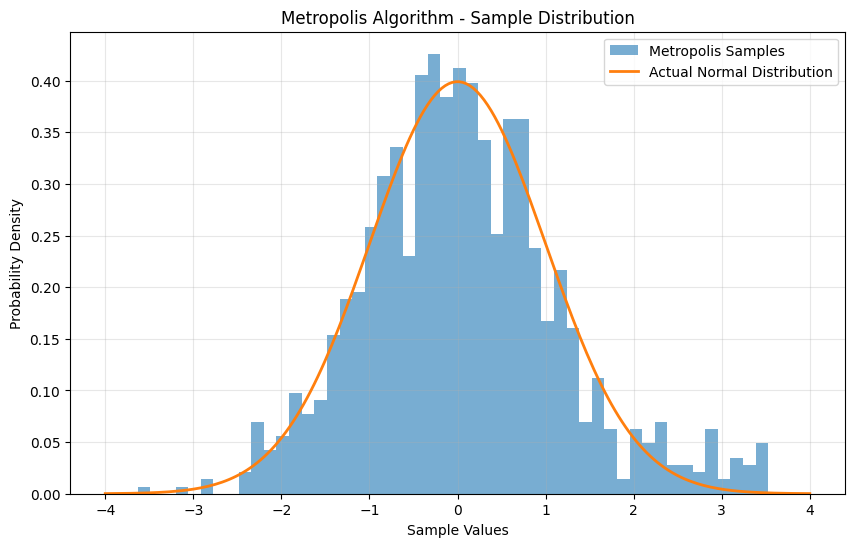

In [9]:
# Plot histogram of generated samples
plt.figure(figsize=(10, 6))
plt.hist(
    samples,
    bins=50,
    density=True,
    alpha=0.6,
    label="Metropolis Samples"
)

# Plot the actual normal distribution
x = np.linspace(-4, 4, 200)
y = norm.pdf(x)
plt.plot(
    x,
    y,
    linewidth=2,
    label="Actual Normal Distribution"
)

plt.title("Metropolis Algorithm - Sample Distribution")
plt.xlabel("Sample Values")
plt.ylabel("Probability Density")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Conclusion (Part A)
The Metropolis Algorithm was successfully implemented using Python. Random samples were generated from a standard normal distribution, and their distribution was visualized using a histogram. The generated samples approximately followed the target probability distribution.

---
# Practical 12 - Part B: Deterministic Model

### Aim
To implement and simulate a deterministic model using Python and visualize its behaviour over time.

### Theory
A deterministic model is a mathematical model in which the output is completely determined by the initial conditions and fixed parameters. It does not involve random variables or unpredictable changes.

For this practical, we use the **Logistic Growth Model**, which describes population growth when resources such as food, water, and space are limited.

### Mathematical Equation
$$\frac{dP}{dt} = rP\left(1 - \frac{P}{K}\right)$$

Where:
- $P =$ Population size
- $r =$ Growth rate
- $K =$ Carrying capacity
- $t =$ Time

The population initially grows rapidly, but growth slows as it approaches the carrying capacity.

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Model parameters
r = 0.2      # Growth rate
K = 1000     # Carrying capacity
P0 = 50      # Initial population

# Time settings
time = np.linspace(0, 50, 200)

print("Growth Rate:", r)
print("Carrying Capacity:", K)
print("Initial Population:", P0)

Growth Rate: 0.2
Carrying Capacity: 1000
Initial Population: 50


### Implement the Logistic Growth Model

Our model is:
$$\frac{dP}{dt} = rP\left(1 - \frac{P}{K}\right)$$

We use **Euler's Method** to calculate population values at small time intervals:
$$P_{\text{next}} = P_{\text{current}} + \Delta t \times rP\left(1 - \frac{P}{K}\right)$$

In [5]:
# Time step
dt = time[1] - time[0]

# Store population values
population = [P0]

# Apply Euler's Method
for i in range(1, len(time)):
    P = population[-1]

    # Calculate population growth
    dP = r * P * (1 - P / K)

    # Calculate next population
    P_next = P + dP * dt
    population.append(P_next)

# Display first 10 values
print("First 10 population values:")
print(population[:10])
print("\nFinal Population:", population[-1])

First 10 population values:
[50, np.float64(52.38693467336683), np.float64(54.88153486175352), np.float64(57.48804501215411), np.float64(60.21081735852771), np.float64(63.05430855609283), np.float64(66.02307552737956), np.float64(69.1217704532733), np.float64(72.35513484034256), np.float64(75.72799259424097)]

Final Population: 999.223460678414


### Visualization of Logistic Growth Model

In this step, we plot population against time using Matplotlib. We expect an S-shaped (sigmoid) curve where population gradually approaches the carrying capacity ($K$).

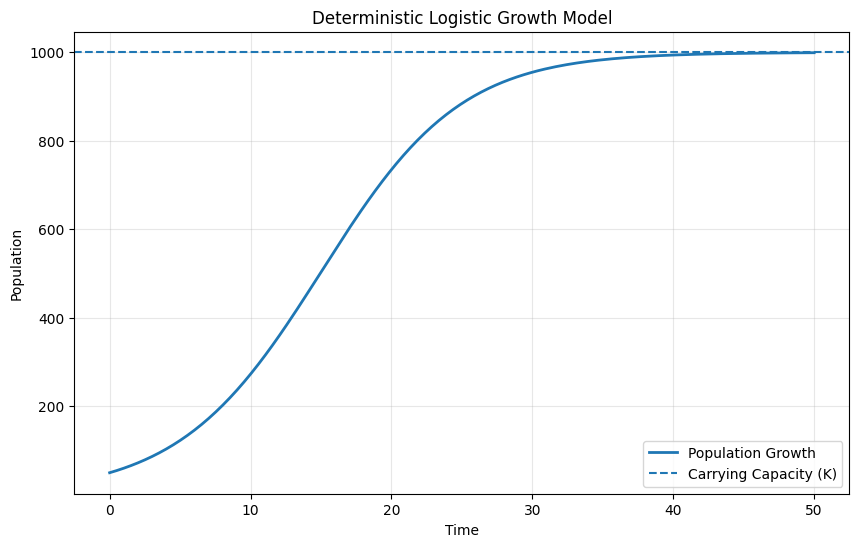

In [6]:
plt.figure(figsize=(10, 6))
plt.plot(
    time,
    population,
    label="Population Growth",
    linewidth=2
)

# Show carrying capacity
plt.axhline(
    y=K,
    linestyle="--",
    label="Carrying Capacity (K)"
)

plt.title("Deterministic Logistic Growth Model")
plt.xlabel("Time")
plt.ylabel("Population")
plt.legend()
plt.grid(alpha=0.3)
plt.show()